# Running Microbe Regressions
While we can run the regressions as done before, I will also try exporting a metadata df and an abundance df for use in R with radEmu. 

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
import statsmodels.api as sm
import scipy.stats.mstats
from regression_functions import *

## Read in required data
- abx use data and covariates
- rarefied count table

### abx data

In [2]:
# Read and sort abx use data
abx_covar = pd.read_csv("../data/abx_covariates_with_statins_a1c_all_covars.csv")
abx_covar = abx_covar.sort_values(by="days_in_program")

### rarefied count table

In [3]:
counts = pd.read_csv("../data/rh_abx_cohort_rarefied_counts.csv" , dtype={'Unnamed: 0':'str'})
counts.rename(columns={'Unnamed: 0':'public_client_id'}, inplace=True)

In [4]:
abx_counts = abx_covar.merge(counts, how='left', on='public_client_id')

## Create microbe name dictionary for plotting
(Made this after running regressions but moving up here for visibility)

In [5]:
microbe_dict = {
     'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera': 'Methanosphaera',
     'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter': 'Methanobrevibacter',
     'Bacteria_Actinobacteria_Actinobacteria_Bifidobacteriales_Bifidobacteriaceae_Bifidobacterium': 'Bifidobacterium',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Atopobium': 'Atopobium',
     'Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces': 'Actinomyces',
     'Bacteria_Actinobacteria_Actinobacteria_Corynebacteriales_Corynebacteriaceae_Corynebacterium': 'Corynebacterium',
     'Bacteria_Actinobacteria_Actinobacteria_Micrococcales_Micrococcaceae_Rothia': 'Rothia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Libanicoccus':'Libanicoccus',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Olsenella':'Olsenella',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriaceae_Collinsella': 'Collinsella',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_nan': 'Coriobacteriales_Incertae_Sedis',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Adlercreutzia': 'Adlercreutzia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Eggerthella': 'Eggerthella',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_DNF00809': 'Eggerthellaceae_DNF00809',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Enterorhabdus': 'Enterorhabdus',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Gordonibacter': 'Gordonibacter',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Senegalimassilia': 'Senegalimassilia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Slackia': 'Slackia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_nan': 'Eggerthellaceae',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_nan_nan': 'Coriobacteriales',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_Raoultibacter': 'Incertae_Sedis_Raoultibacter',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides': 'Bacteroides',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Barnesiella': 'Barnesiella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Coprobacter': 'Coprobacter',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_nan': 'Barnesiellaceae',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Butyricimonas': 'Butyricimonas',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Odoribacter': 'Odoribacter',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Sanguibacteroides': 'Sanguibacteroides',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Muribaculaceae_nan': 'Muribaculaceae',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Alloprevotella': 'Alloprevotella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Porphyromonadaceae_Porphyromonas':'Porphyromonas',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotellaceae_NK3B31_group': 'Prevotellaceae_NK3B31_group',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Paraprevotella': 'Paraprevotella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella': 'Prevotella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_2':'Prevotella_2',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_6':'Prevotella_6',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_nan':'Prevotellaceae',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_7': 'Prevotella_7',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_9': 'Prevotella_9',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_nan_nan': 'Bacteroidales',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Alistipes': 'Alistipes',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Rikenellaceae_RC9_gut_group':'Rikenellaceae_RC9',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides': 'Parabacteroides',
     'Bacteria_Bacteroidetes_Bacteroidia_Flavobacteriales_nan_nan': 'Flavobacteriales',
     'Bacteria_Cyanobacteria_Oxyphotobacteria_Chloroplast_nan_nan': 'Oxyphotobacteria_Chloroplast',
     'Bacteria_Cyanobacteria_Melainabacteria_Gastranaerophilales_nan_nan': 'Gastranaerophilales',
     'Bacteria_Epsilonbacteraeota_Campylobacteria_Campylobacterales_Campylobacteraceae_Campylobacter':'Campylobacter',
     'Bacteria_Firmicutes_Bacilli_Bacillales_Staphylococcaceae_Staphylococcus': 'Staphylococcus',
     'Bacteria_Firmicutes_Bacilli_Bacillales_Family_XI_Gemella': 'Gemella',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Carnobacteriaceae_Granulicatella': 'Granulicatella',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Enterococcaceae_Enterococcus': 'Enterococcus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Pediococcus': 'Pediococcus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Lactobacillus': 'Lactobacillus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Lactococcus': 'Lactococcus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Streptococcus': 'Streptococcus',
    'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Weissella':'Weissella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Catabacter': 'Catabacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenella':'Christensenella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group': 'Christensenellaceae_R7',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_nan': 'Christensenellaceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiaceae_1_Clostridium_sensu_stricto_1': 'Clostridium_sensu_stricto_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiales_vadinBB60_group_nan': 'Clostridiales_vadinBB60',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Defluviitaleaceae_Defluviitaleaceae_UCG011': 'Defluviitaleaceae_UCG011',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Anaerofustis': 'Anaerofustis',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Eubacterium': 'Eubacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Murdochiella': 'Murdochiella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Parvimonas':'Parvimonas',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_AD3011_group': 'Clostridiales_Family_XIII_AD3011',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_UCG001': 'Clostridiales_Family_XIII_UCG001',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_nan': 'Clostridiales_Family_XIII',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Mogibacterium':'Mogibacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerosporobacter': 'Anaerosporobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Agathobacter': 'Agathobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerostipes': 'Anaerostipes',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Blautia': 'Blautia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_CAG56': 'Lachnospiraceae_CAG56',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_1': 'Coprococcus_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_2': 'Coprococcus_2',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_3': 'Coprococcus_3',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Cuneatibacter': 'Cuneatibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Butyrivibrio':'Butyrivibrio',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Dorea': 'Dorea',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Eisenbergiella': 'Eisenbergiella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Fusicatenibacter': 'Fusicatenibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_FD2005': 'Lachnospiraceae_FD2005',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066575': 'Lachnospiraceae_GCA900066575',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Herbinix': 'Herbinix',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Howardella': 'Howardella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Hungatella': 'Hungatella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnoclostridium': 'Lachnoclostridium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospira': 'Lachnospira',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_AC2044_group': 'Lachnospiraceae_AC2044_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_FCS020_group': 'Lachnospiraceae_FCS020',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066755': 'Lachnospiraceae_GCA900066755',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_ND3007_group': 'Lachnospiraceae_ND3007',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4A136_group': 'Lachnospiraceae_NK4A136',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4B4_group': 'Lachnospiraceae_NK4B4_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_nan': 'Lachnospiraceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_284':'Lachnospiraceae_284',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NC2004_group':'Lachnospiraceae_NC2004_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG001': 'Lachnospiraceae_UCG001',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG003': 'Lachnospiraceae_UCG003',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG004': 'Lachnospiraceae_UCG004',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG008': 'Lachnospiraceae_UCG008',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG010': 'Lachnospiraceae_UCG010',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lactonifactor': 'Lactonifactor',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Marvinbryantia': 'Marvinbryantia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Roseburia': 'Roseburia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas': 'Sellimonas',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Syntrophococcus': 'Syntrophococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella': 'Tyzzerella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_3': 'Tyzzerella_3',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_4': 'Tyzzerella_4',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_UC512E3': 'Lachnospiraceae_UC512E3',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Dehalobacterium':'Dehalobacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Peptococcus': 'Peptococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_nan': 'Peptococcaceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Intestinibacter': 'Intestinibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Peptostreptococcus':'Peptostreptococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Romboutsia': 'Romboutsia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Acetanaerobacterium': 'Acetanaerobacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerofilum': 'Anaerofilum',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Angelakisella': 'Angelakisella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerotruncus': 'Anaerotruncus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Butyricicoccus': 'Butyricicoccus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Caproiciproducens': 'Caproiciproducens',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Candidatus_Soleaferrea': 'Candidatus_Soleaferrea',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_DTU089': 'Ruminococcaceae_DTU089',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Faecalibacterium': 'Faecalibacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Flavonifractor': 'Flavonifractor',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Fournierella': 'Fournierella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_GCA900066225': 'Ruminococcaceae_GCA900066225',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Harryflintia': 'Harryflintia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Hydrogenoanaerobacterium': 'Hydrogenoanaerobacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Intestinimonas': 'Intestinimonas',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Negativibacillus': 'Negativibacillus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillibacter': 'Oscillibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillospira': 'Oscillospira',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Papillibacter': 'Papillibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Phocea': 'Phocea',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pseudoflavonifractor': 'Pseudoflavonifractor',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pygmaiobacter': 'Pygmaiobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_NK4A214_group': 'Ruminococcaceae_NK4A214',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium': 'Ruminiclostridium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_1': 'Ruminiclostridium_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_5': 'Ruminiclostridium_5',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_6': 'Ruminiclostridium_6',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_9': 'Ruminiclostridium_9',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG002': 'Ruminococcaceae_UCG002',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG003': 'Ruminococcaceae_UCG003',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG004': 'Ruminococcaceae_UCG004',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG005': 'Ruminococcaceae_UCG005',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG007': 'Ruminococcaceae_UCG007',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG008': 'Ruminococcaceae_UCG008',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG009': 'Ruminococcaceae_UCG009',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG010': 'Ruminococcaceae_UCG010',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG011': 'Ruminococcaceae_UCG011',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG013': 'Ruminococcaceae_UCG013',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG014': 'Ruminococcaceae_UCG014',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_1': 'Ruminococcus_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_2': 'Ruminococcus_2',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Subdoligranulum': 'Subdoligranulum',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_UBA1819': 'Ruminococcaceae_UBA1819',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_V9D2013_group':'Ruminococcaceae_V9D2013_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_nan': 'Ruminococcaceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_nan_nan': 'Clostridiales',
     'Bacteria_Firmicutes_Clostridia_DTU014_nan_nan': 'Clostridia_DTU014',
     'Bacteria_Firmicutes_Clostridia_nan_nan_nan': 'Clostridia',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Coprobacillus': 'Coprobacillus',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Dielma': 'Dielma',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelatoclostridium': 'Erysipelatoclostridium',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG003': 'Erysipelotrichaceae_UCG003',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG004': 'Erysipelotrichaceae_UCG004',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Faecalitalea': 'Faecalitalea',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemania': 'Holdemania',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemanella': 'Holdemanella',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Kandleria': 'Kandleria',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Merdibacter': 'Merdibacter',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_nan': 'Erysipelotrichaceae',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Candidatus_Stoquefichus': 'Candidatus_Stoquefichus',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Acidaminococcus': 'Acidaminococcus',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Phascolarctobacterium': 'Phascolarctobacterium',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Allisonella': 'Allisonella',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Dialister': 'Dialister',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Veillonella': 'Veillonella',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_nan': 'Veillonellaceae',
     'Bacteria_Fusobacteria_Fusobacteriia_Fusobacteriales_Fusobacteriaceae_Fusobacterium': 'Fusobacterium',
     'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_Victivallis': 'Victivallis',
     'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_nan': 'Victivallaceae',
     'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_vadinBE97_nan': 'Victivallales_vadinBE97',
     'Bacteria_Patescibacteria_Saccharimonadia_Saccharimonadales_Saccharimonadaceae_nan': 'Saccharimonadaceae',
     'Bacteria_Proteobacteria_Alphaproteobacteria_Rhodospirillales_nan_nan': 'Rhodospirillales',
     'Bacteria_Proteobacteria_Alphaproteobacteria_Rickettsiales_Mitochondria_nan': 'Rickettsiales_Mitochondria',
     'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Bilophila': 'Bilophila',
     'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Desulfovibrio': 'Desulfovibrio',
     'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_nan': 'Desulfovibrionaceae',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter': 'Oxalobacter',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella': 'Parasutterella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella': 'Sutterella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Citrobacter': 'Citrobacter',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella': 'Escherichia_Shigella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Enterobacter': 'Enterobacter',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_nan': 'Enterobacteriaceae',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus': 'Haemophilus',
     'Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma': 'Anaeroplasma',
     'Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan': 'Izimaplasmatales',
     'Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan': 'Mollicutes_RF39',
     'Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia': 'Akkermansia',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Leuconostoc': 'Leuconostoc',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Anaerococcus': 'Anaerococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Ezakiella': 'Ezakiella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Finegoldia': 'Finegoldia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Peptoniphilus': 'Peptoniphilus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Shuttleworthia': 'Shuttleworthia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Terrisporobacter': 'Terrisporobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_CAG352': 'Ruminococcaceae_CAG352',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Asteroleplasma':'Asteroleplasma',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Catenibacterium': 'Catenibacterium',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Solobacterium': 'Solobacterium',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Turicibacter': 'Turicibacter',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megamonas':'Megamonas',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megasphaera': 'Megasphaera',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella': 'Klebsiella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Pseudomonadales_Pseudomonadaceae_Pseudomonas':'Pseudomonas',
     'Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus': 'Cloacibacillus',
     'Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan':'Puniceicoccaceae'}

In [6]:
# result = microbe_dict_1 | microbe_dict_2

In [7]:
# result

## Prevalence filtering
Prevalence filters for logistic regression determined in this section.

In [8]:
# abx_counts.columns[26:].tolist()

In [9]:
microbe_col = abx_counts.columns[26:].tolist()

In [10]:
# Missingness between 0.05 (highly prevalent) and 0.95 (high sparsity)
# Here the sum is the number of bugs retained for testing
five_ninetyfive_thresh = ((0.95 > abx_counts[microbe_col].eq(0).sum() / abx_counts[microbe_col].shape[0]) & 
(abx_counts[microbe_col].eq(0).sum() / abx_counts[microbe_col].shape[0] > 0.05))

# Try a few things to increase testing window
five_ninetyseven_thresh = ((0.95 > abx_counts[microbe_col].eq(0).sum() / abx_counts[microbe_col].shape[0]) & 
(abx_counts[microbe_col].eq(0).sum() / abx_counts[microbe_col].shape[0] > 0.025))

three_ninetyeven_thresh = ((0.965 > abx_counts[microbe_col].eq(0).sum() / abx_counts[microbe_col].shape[0]) & 
(abx_counts[microbe_col].eq(0).sum() / abx_counts[microbe_col].shape[0] > 0.025))

In [11]:
print(f'Taxa tested with 5% to 95% prevalence: {five_ninetyfive_thresh.sum()} \n 5% to 97.5% prevalence: {five_ninetyseven_thresh.sum()} \n 3.5% to 97.5% prevalence: {three_ninetyeven_thresh.sum()}')

Taxa tested with 5% to 95% prevalence: 191 
 5% to 97.5% prevalence: 199 
 3.5% to 97.5% prevalence: 215


**Which bugs am I missing due to the prevalence filtering?**

In [12]:
bottom_thresh = (0.965 > (abx_counts[microbe_col].eq(0).sum() /
                         abx_counts[microbe_col].shape[0]))

top_thresh = (abx_counts[microbe_col].eq(0).sum() /
               abx_counts[microbe_col].shape[0]) > 0.025      

In [13]:
common_bugs_not_tested = top_thresh[~top_thresh].index
common_bugs_not_tested

Index(['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides',
       'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Streptococcus',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerostipes',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Blautia',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnoclostridium',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_nan',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Butyricicoccus',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_5',
       'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_nan'],
      dtype='object')

In [14]:
rare_bugs_not_tested = bottom_thresh[~bottom_thresh].index

In [15]:
len(rare_bugs_not_tested)

290

In [16]:
# Sanity check to ensure this == the number of bugs tested
len(microbe_col) - ((len(common_bugs_not_tested) + len(rare_bugs_not_tested)))

215

In [17]:
# Use this to check the number of individuals that LACK a taxon
# relative_abundance['Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus'].eq(0).sum()

## Prepare data for logistic regression

In [18]:
# Minimal prevalence filtering 
taxa_pa_filtered = abx_counts.drop(columns=three_ninetyeven_thresh[~three_ninetyeven_thresh].index)

In [19]:
# taxa_pa_filtered.columns[26:]

In [20]:
microbe_features = taxa_pa_filtered.columns[26:]

In [21]:
taxa_pa_filtered[microbe_features] = (taxa_pa_filtered[microbe_features] != 0).astype(int)

In [22]:
taxa_pa_filtered.columns[taxa_pa_filtered.columns.str.contains("Shigella")]

Index(['Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia.Shigella'], dtype='object')

In [23]:
# Remove hyphen; it stops the regression
taxa_pa_filtered.columns = taxa_pa_filtered.columns.str.replace("-","")
taxa_pa_filtered.columns = taxa_pa_filtered.columns.str.replace("/","_")
taxa_pa_filtered.columns = taxa_pa_filtered.columns.str.replace("Escherichia.Shigella","Escherichia_Shigella")
taxa_pa_filtered.columns = taxa_pa_filtered.columns.str.replace(".","")

In [24]:
microbe_features = taxa_pa_filtered.columns[26:]

In [25]:
len(microbe_features)

215

In [26]:
vendor_rm = taxa_pa_filtered[taxa_pa_filtered["vendor_dashboard"] == 'research-microbiome']
vendor_sg = taxa_pa_filtered[taxa_pa_filtered["vendor_dashboard"] == 'Second Genome']

In [27]:
microbe_features[vendor_rm[microbe_features].sum(axis=0) == 0].tolist()

['Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Herbinix',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Syntrophococcus']

In [28]:
microbe_features[vendor_sg[microbe_features].sum(axis=0) == 0].tolist()

['Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Kandleria',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Enterobacter']

In [29]:
# microbe_features_pa
items_to_remove = {'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Syntrophococcus',
                   'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Kandleria',
                   'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Enterobacter',
                   'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Herbinix'}
microbe_features_to_test = [item for item in microbe_features if item not in items_to_remove]

In [30]:
len(microbe_features_to_test)

211

In [69]:
# taxa_pa_filtered.columns.tolist()

In [32]:
taxa_pa_filtered.to_csv('../data/abx_microbes_pa_rarefied.csv')

## Run logistic regressions

In [33]:
formula = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
           "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) + "
           "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + C(vendor_dashboard)")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"
chol_term = "C(meds_cholesterol)[T.Yes]"
sugar_term = "C(meds_blood_sugar)[T.Yes]"

In [34]:
# taxa_pa_filtered.columns.tolist()

### Three months

In [35]:
tests_threemo_logit = run_logit_tests(microbe_features_to_test, taxa_pa_filtered, formula, abx_term_three)

In [36]:
tests_threemo_logit.reset_index(inplace=True)

In [37]:
three_decreased = tests_threemo_logit[(tests_threemo_logit['q']<0.1) & (tests_threemo_logit['OR']<1)]
three_increased = tests_threemo_logit[(tests_threemo_logit['q']<0.1) & (tests_threemo_logit['OR']>1)]
sig_logit_three = tests_threemo_logit[(tests_threemo_logit['q']<0.1)]

In [38]:
# sig_logit_three
# three_decreased.feature.tolist()

In [39]:
# len(sig_logit_three.feature.tolist())

### Twelve months

In [40]:
tests_twelvemo_logit = run_logit_tests(microbe_features_to_test, taxa_pa_filtered, formula, abx_term_twelve)
tests_twelvemo_logit.reset_index(inplace=True)

In [41]:
sig_logit_twelve = tests_twelvemo_logit[(tests_twelvemo_logit['q']<0.1)]

In [42]:
len(sig_logit_twelve)

77

In [43]:
len(set(sig_logit_three.feature.tolist() + sig_logit_twelve.feature.tolist()))

131

In [44]:
microbe_sig_feats = set(sig_logit_three.feature.tolist() + sig_logit_twelve.feature.tolist())

### Cholesterol lowering medication use

In [45]:
tests_chol_logit = run_logit_tests(microbe_features_to_test, taxa_pa_filtered, formula, chol_term)

In [46]:
# tests_chol_logit

In [47]:
tests_chol_logit.reset_index(inplace=True)
sig_chol_logit = tests_chol_logit[(tests_chol_logit['q']<0.1)]
sig_chol_logit_subset = sig_chol_logit[sig_chol_logit.feature.isin(microbe_sig_feats)]

### Blood sugar lowering medication use

In [48]:
tests_sugar_logit = run_logit_tests(microbe_features_to_test, taxa_pa_filtered, formula, sugar_term)

In [49]:
tests_sugar_logit

,coef,OR,conf_low,conf_high,OR_conf_low,OR_conf_high,p,n,q
feature,,,,,,,,,
Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,0.284570,1.329190,-0.233027,0.802167,0.792132,2.230369,0.281226,1970,0.629897
Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,0.207106,1.230113,-0.900397,1.314609,0.406408,3.723294,0.713978,1970,0.875868
Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,-0.016518,0.983618,-0.474045,0.441009,0.622479,1.554274,0.943588,1970,0.979241
Bacteria_Actinobacteria_Actinobacteria_Bifidobacteriales_Bifidobacteriaceae_Bifidobacterium,-0.227555,0.796478,-0.753820,0.298709,0.470566,1.348117,0.396726,1970,0.717572
Bacteria_Actinobacteria_Actinobacteria_Corynebacteriales_Corynebacteriaceae_Corynebacterium,0.579514,1.785171,-0.358001,1.517029,0.699073,4.558661,0.225693,1970,0.573749
...,...,...,...,...,...,...,...,...,...
Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma,0.642650,1.901513,-0.486914,1.772214,0.614520,5.883865,0.264810,1970,0.620832
Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,0.155882,1.168689,-0.424998,0.736762,0.653771,2.089161,0.598911,1970,0.810066
Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,-0.069252,0.933092,-0.626118,0.487615,0.534663,1.628428,0.807432,1970,0.935420


In [50]:
tests_sugar_logit.reset_index(inplace=True)
sig_sugar_logit = tests_sugar_logit[(tests_sugar_logit['q']<0.1)]
sig_sugar_logit_subset = sig_sugar_logit[sig_sugar_logit.feature.isin(microbe_sig_feats)]

### To plot in R, grab prevalence and phyla info

**Create phyla dataframe and calculate prevalence**

In [51]:
taxa_grab_phyla = pd.read_csv("../data/tax_genus_level.csv")

In [52]:
# Remember we removed special char for regression
# Change these to match
taxa_grab_phyla.taxa_genus_level = taxa_grab_phyla.taxa_genus_level.str.replace("-","")
taxa_grab_phyla.taxa_genus_level = taxa_grab_phyla.taxa_genus_level.str.replace("/","_")
taxa_grab_phyla.taxa_genus_level = taxa_grab_phyla.taxa_genus_level.str.replace(".","")

In [53]:
taxa_prevalence = taxa_pa_filtered[microbe_features].sum() / taxa_pa_filtered[microbe_features].shape[0]

# taxa_prevalence
taxa_prevalence['Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus']

0.482741116751269

## To make a heatmap, we should combine these into two sheets: ORs and q-values

In [54]:
# # Obtain bugs significant for any cov
# sig_microbes_all_logit = list(set(sig_logit_three['feature'].tolist() + 
#                                   sig_logit_twelve['feature'].tolist() + 
#                                   sig_chol_logit['feature'].tolist() + 
#                                   tests_sugar_logit['feature'].tolist()))

# Add three month betas
microbe_ors = tests_threemo_logit[['feature','OR']].copy().rename(
     columns={'OR':'abx_three'})

# Add twelve month betas
microbe_ors = microbe_ors.merge(tests_twelvemo_logit[['feature','OR']].copy(),
                                    how='left', on='feature').rename(columns={'OR':'abx_twelve'})

# Add cholesterol medication use betas
microbe_ors = microbe_ors.merge(tests_sugar_logit[['feature','OR']].copy(),
                                    how='left', on='feature').rename(columns={'OR':'meds_cholesterol'})

# Add blood sugar medication use betas
microbe_ors = microbe_ors.merge(tests_chol_logit[['feature','OR']].copy(),
                                    how='left', on='feature').rename(columns={'OR':'meds_blood_sugar'})

microbe_ors = microbe_ors[microbe_ors.feature.isin(microbe_sig_feats)]

In [55]:
# Add three month 
microbe_logit_q = tests_threemo_logit[['feature','q']].copy().rename(columns={'q':'abx_three'})

# Add twelve month 
microbe_logit_q = microbe_logit_q.merge(tests_twelvemo_logit[['feature','q']].copy(),
                                    how='left', on='feature').rename(columns={'q':'abx_twelve'})

# Add cholesterol medication use 
microbe_logit_q = microbe_logit_q.merge(tests_chol_logit[['feature','q']].copy(),
                                    how='left', on='feature').rename(columns={'q':'meds_cholesterol'})

# Add blood sugar medication use 
microbe_logit_q = microbe_logit_q.merge(tests_sugar_logit[['feature','q']].copy(),
                                    how='left', on='feature').rename(columns={'q':'meds_blood_sugar'})

microbe_logit_q = microbe_logit_q[microbe_logit_q.feature.isin(microbe_sig_feats)]

In [56]:
microbe_ors['plot_name'] = microbe_ors['feature'].apply(lambda x: microbe_dict[x])
microbe_logit_q['plot_name'] = microbe_logit_q['feature'].apply(lambda x: microbe_dict[x])

In [57]:
microbe_ors = microbe_ors.merge(taxa_grab_phyla, how = 'left', left_on='feature',
                                    right_on='taxa_genus_level')
microbe_ors.drop(columns='taxa_genus_level', inplace=True)
microbe_ors['prevalence'] = microbe_ors['feature'].apply(lambda x: taxa_prevalence[x])
microbe_ors['prevalence_bins'] = pd.cut(microbe_ors.prevalence, [0.035, .25, .5, .75, 0.975])

In [58]:
microbe_ors.to_csv("../data/sig_logit_all_ors_rarefied.csv", index=False)
microbe_logit_q.to_csv("../data/sig_logit_all_qs_rarefied.csv", index=False)

In [59]:
# microbe_logit_q

## Plot proportion of three example taxon

In [60]:
taxa_pa_filtered["abx_recency"] = pd.Categorical(
    taxa_pa_filtered["abx_recency"],
    categories=["none", "twelve", "three"],
    ordered=True
)

binary_pal = {0: "white", 1: "black"}

In [61]:
sellimonas_prop_df = (
    taxa_pa_filtered
    .groupby(["abx_recency", "Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas"], 
             observed=False)
    .size()
    .reset_index(name="n")
)

sellimonas_prop_df["proportion"] = sellimonas_prop_df["n"] / sellimonas_prop_df.groupby("abx_recency",  observed=False)["n"].transform("sum")

sellimonas_prop_df = sellimonas_prop_df.sort_values(
    by="Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas", ascending=False)

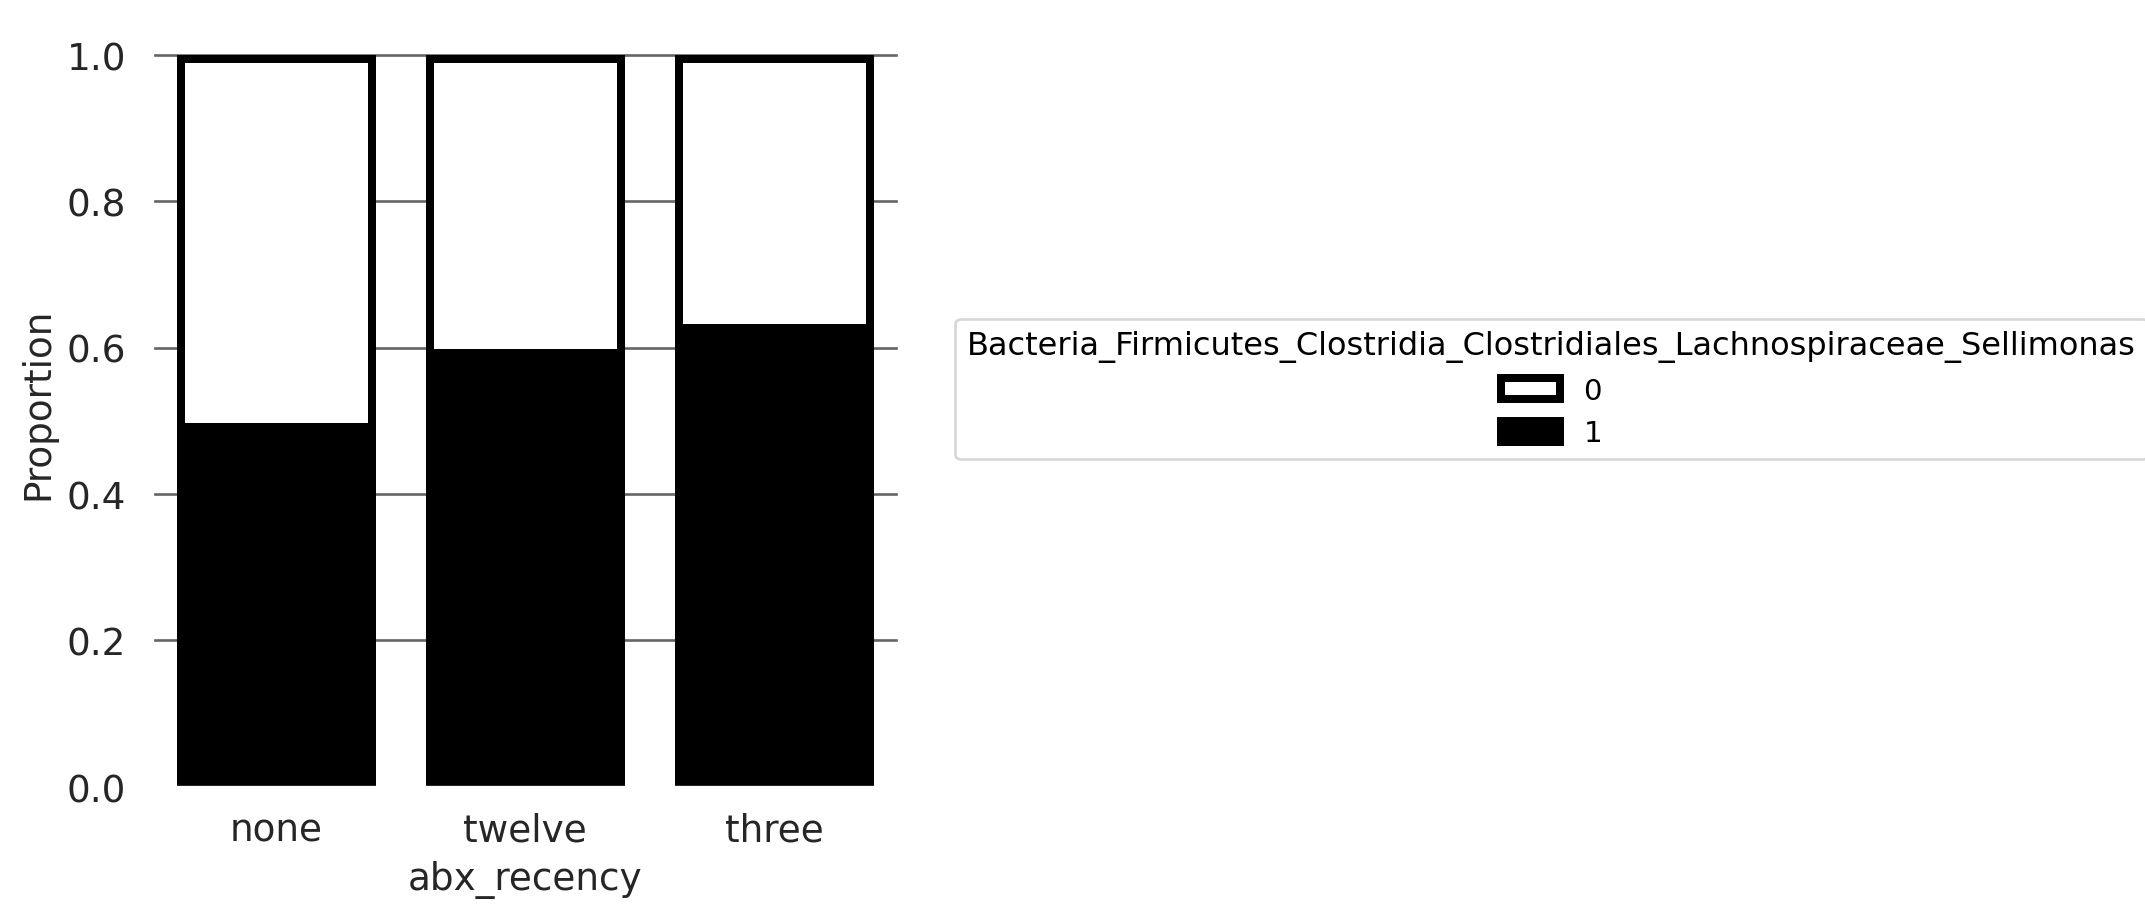

In [62]:
sellimonas_proportion = (
    so.Plot(sellimonas_prop_df, x="abx_recency", y="proportion",
            color="Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas")
    .add(so.Bar(alpha=1, edgewidth=3, edgecolor="black"), so.Stack(), legend=True) # 
    .scale(color=so.Nominal(binary_pal),  order=[1,0]) 
    .label(y="Proportion")
    .theme({
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "0.4",         # Lower number = darker grid (0 is black, 1 is white)
        "font.size": 14,             # Sets base font size to 12pt
        "axes.labelsize": 14,        # Ensures axis labels are 12pt
        "xtick.labelsize": 14,       # Ensures tick labels are 12pt
        "ytick.labelsize": 14
    })
    .layout(size=(5, 5))    
)

sellimonas_proportion.save("figures/sellimonas_proportion.pdf")

In [63]:
parabacteroides_prop_df = (
    taxa_pa_filtered
    .groupby(["abx_recency", "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides"], 
             observed=False)
    .size()
    .reset_index(name="n")
)

parabacteroides_prop_df["proportion"] = parabacteroides_prop_df["n"] / parabacteroides_prop_df.groupby(
    "abx_recency",  observed=False)["n"].transform("sum")

parabacteroides_prop_df = parabacteroides_prop_df.sort_values(
    by="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides", ascending=False)

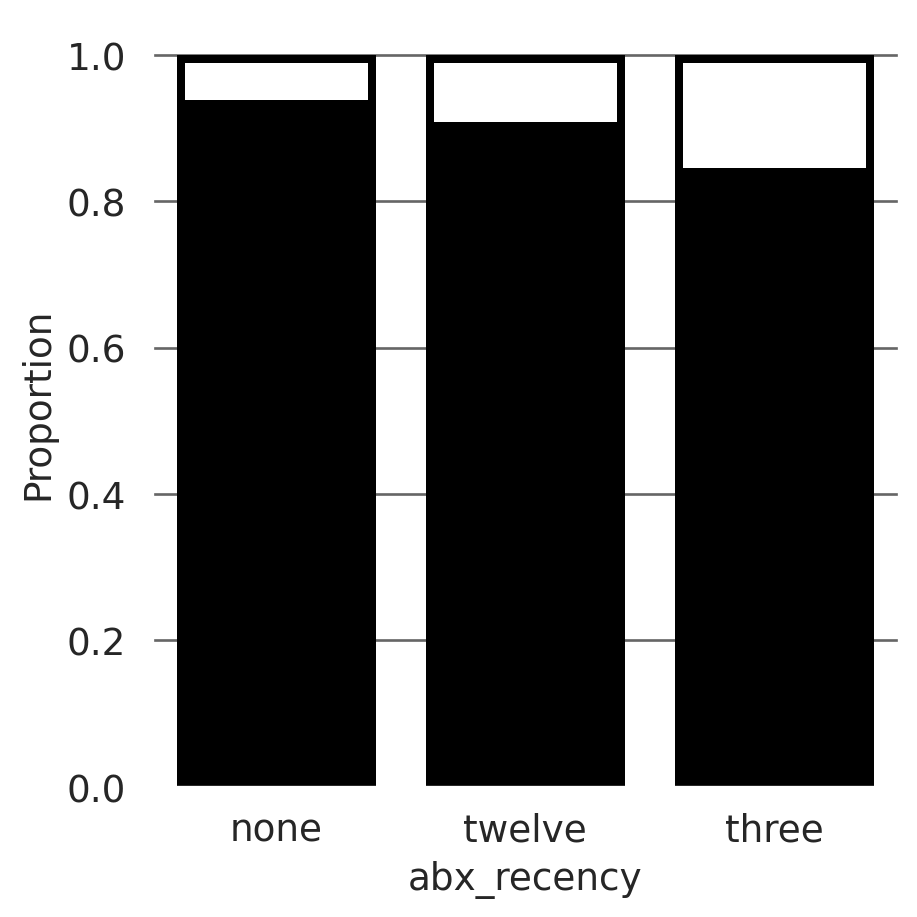

In [64]:
parabacteroides_proportion = (
    so.Plot(parabacteroides_prop_df, x="abx_recency", y="proportion",
            color="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides")
    .add(so.Bar(alpha=1, edgewidth=3, edgecolor="black"), so.Stack(), legend=False) # 
    .scale(color=so.Nominal(binary_pal),  order=[1,0]) 
    .label(y="Proportion")
    .theme({
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "0.4",         # Lower number = darker grid (0 is black, 1 is white)
        "font.size": 14,             # Sets base font size to 12pt
        "axes.labelsize": 14,        # Ensures axis labels are 12pt
        "xtick.labelsize": 14,       # Ensures tick labels are 12pt
        "ytick.labelsize": 14
    })
    .layout(size=(5, 5))    
)

parabacteroides_proportion.save("figures/parabacteroides_proportion.pdf")

In [65]:
christensenellaceae_prop_df = (
    taxa_pa_filtered
    .groupby(["abx_recency",
              "Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group"],  observed=False)
    .size()
    .reset_index(name="n")
)

christensenellaceae_prop_df["proportion"] = christensenellaceae_prop_df["n"] / christensenellaceae_prop_df.groupby(
    "abx_recency", observed=False)["n"].transform("sum")

In [66]:
christensenellaceae_prop_df = christensenellaceae_prop_df.sort_values(
    by="Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group", ascending=False)

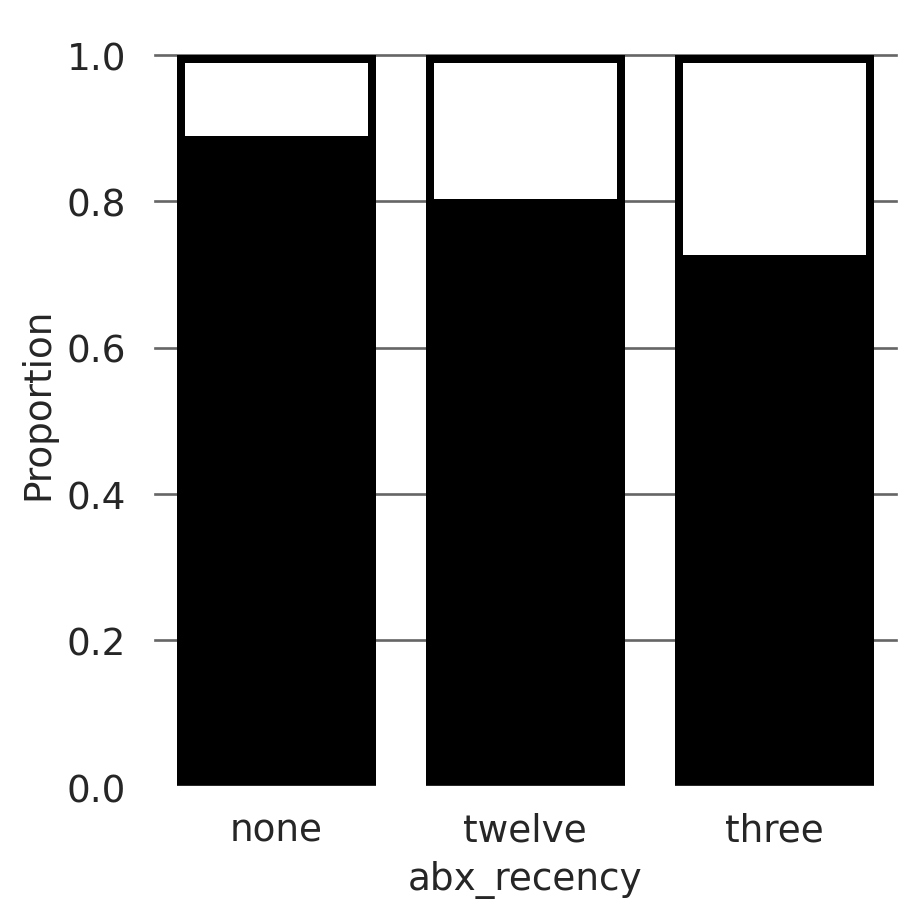

In [67]:
christensenellaceae_proportion = (
    so.Plot(christensenellaceae_prop_df, x="abx_recency", y="proportion",
            color="Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group")
    .add(so.Bar(alpha=1, edgewidth=3, edgecolor="black"), so.Stack(), legend=False) # 
    .scale(color=so.Nominal(binary_pal),  order=[1,0]) 
    .label(y="Proportion")
    .theme({
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "0.4",         # Lower number = darker grid (0 is black, 1 is white)
        "font.size": 14,             # Sets base font size to 12pt
        "axes.labelsize": 14,        # Ensures axis labels are 12pt
        "xtick.labelsize": 14,       # Ensures tick labels are 12pt
        "ytick.labelsize": 14
    })
    .layout(size=(5, 5))    
)
christensenellaceae_proportion.save("figures/christensenellaceae_proportion.pdf")